# Lab 02 Home Assignment: Two-Source Comparison of Sentiment and Noun Density

**Question.** Do two different blogs differ in (a) mean sentiment polarity and (b) mean noun density (nouns per token)?

**Pipeline.** feed discovery -> polite scraping -> cached CSV -> spaCy + TextBlob features -> statistics -> grouped bar chart -> report.

**Design choices**
- 10 articles per source, 20 in total, each record labelled with its `source`.
- URLs are discovered from each blog's RSS feed, so you are not hand-picking articles (less selection bias). A manual list is supported as a fallback.
- The extractor is selector-agnostic: it tries `<article>`, then the container holding the most paragraph text. This avoids the brittle-selector failure from Exercise 1.
- Raw scrape is cached to `two_source_corpus.csv`, so everything after Step 2 runs offline and is reproducible.
- **Noun density** = `num_nouns / num_tokens`. Raw noun counts would just measure article length.

In [6]:
# Step 0: install (run once), then imports
# !pip install requests beautifulsoup4 lxml pandas spacy matplotlib seaborn textblob scipy
# !python -m spacy download en_core_web_sm
# !python -m textblob.download_corpora   # only if TextBlob asks for corpora

import os, re, time
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("figures", exist_ok=True)
rng = np.random.default_rng(42)          # fixed seed: bootstrap/permutation results are reproducible
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

## Step 1: Configure the two sources

Pick two blogs that are genuinely different (e.g. a promotional/affiliate blog vs. an editorial/engineering blog).
Each needs a public RSS or Atom feed. Change `feed` (or fill `urls` by hand) to use your own choices.

In [7]:
N_PER_SOURCE = 10

SOURCES = [
    {   # Source A: the blog used in the lab (Blogger, promotional style)
        "name": "techncruncher",
        "feed": "https://techncruncher.blogspot.com/feeds/posts/default?alt=rss&max-results=30",
        "urls": [],      # optional manual override; if non-empty the feed is ignored
    },
    {   # Source B: a different, editorial-style blog (WordPress). Replace if it blocks you.
        "name": "second-blog",
        "feed": "https://www.smashingmagazine.com/feed/",
        "urls": [],
    },
]

In [8]:
def discover_urls(source, n=N_PER_SOURCE):
    """Return up to n article URLs from a manual list or the source's RSS/Atom feed."""
    if source["urls"]:
        return source["urls"][:n]
    res = requests.get(source["feed"], headers=headers, timeout=15)
    res.raise_for_status()
    soup = BeautifulSoup(res.content, "xml")
    urls = []
    for item in soup.find_all("item"):                      # RSS 2.0
        link = item.find("link")
        if link and link.get_text(strip=True):
            urls.append(link.get_text(strip=True))
    if not urls:                                            # Atom fallback
        for entry in soup.find_all("entry"):
            link = entry.find("link", rel="alternate")
            if link and link.get("href"):
                urls.append(link["href"])
    return urls[:n + 10]     # a few spares in case some pages are skipped


def extract_article(html):
    """Selector-agnostic extraction: returns (title, text)."""
    soup = BeautifulSoup(html, "lxml")
    for t in soup(["script", "style", "nav", "footer", "header", "aside", "form", "noscript"]):
        t.decompose()

    # Title: og:title -> h1 -> <title>
    og = soup.find("meta", property="og:title")
    h1 = soup.find("h1")
    if og and og.get("content"):
        title = og["content"].strip()
    elif h1:
        title = h1.get_text(strip=True)
    else:
        title = soup.title.get_text(strip=True) if soup.title else ""

    # Body: <article> if present, else the element whose direct <p> children hold the most text
    block = soup.find("article")
    if block is None or len(block.find_all("p")) < 3:
        best, best_len = None, 0
        for el in soup.find_all(["div", "section", "main"]):
            n = sum(len(p.get_text(strip=True)) for p in el.find_all("p", recursive=False))
            if n > best_len:
                best, best_len = el, n
        block = best
    if block is None:
        return title, ""
    text = " ".join(p.get_text(" ", strip=True) for p in block.find_all("p"))
    return title, re.sub(r"\s+", " ", text).strip()


def scrape_source(source, n=N_PER_SOURCE, min_chars=500):
    rows = []
    try:
        urls = discover_urls(source, n)
    except Exception as e:
        print(f"[ERROR] feed for {source['name']}: {e}")
        return pd.DataFrame(rows)
    fails = 0
    for url in urls:
        if len(rows) >= n:
            break
        if fails >= 3:
            print(f"[ABORT] {source['name']}: 3 connection failures in a row; host unreachable from this network.")
            break
        try:
            res = requests.get(url, headers=headers, timeout=(5, 15))
            res.raise_for_status()
            title, text = extract_article(res.content)
            if len(text) < min_chars:
                print(f"[SKIP] too short ({len(text)} chars): {url}")
            else:
                rows.append({"source": source["name"], "url": url, "title": title, "text": text})
            fails = 0
        except requests.exceptions.ConnectionError as e:
            fails += 1
            print(f"[ERROR] {url} -> connection failed")
        except Exception as e:
            print(f"[ERROR] {url} -> {e}")
        time.sleep(1.5)                                     # be polite
    print(f"{source['name']}: {len(rows)} articles")
    return pd.DataFrame(rows)

## Step 2: Scrape (or load the cached copy)

In [9]:
N_PER_SOURCE = 5

SOURCES = [
    {
        "name": "technology-review",
        "feed": "https://www.technologyreview.com/feed/",
        "urls": [],
    },
    {
        "name": "second-blog",
        "feed": "https://www.smashingmagazine.com/feed/",
        "urls": [],
    },
]

## Step 3: Feature engineering

`num_tokens` and `num_nouns` use spaCy; `noun_density = num_nouns / num_alpha_tokens` (punctuation and numbers are excluded from the
denominator so that formatting differences between blogs do not distort it). Polarity and subjectivity use TextBlob.

In [10]:
import spacy
from textblob import TextBlob

nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
nlp.max_length = 3_000_000

def linguistic_features(text):
    doc = nlp(text)
    alpha = [t for t in doc if t.is_alpha]
    nouns = [t for t in alpha if t.pos_ == "NOUN"]            # common nouns, as in the lab
    return pd.Series({
        "num_tokens": len(doc),
        "num_alpha_tokens": len(alpha),
        "num_nouns": len(nouns),
        "noun_density": len(nouns) / len(alpha) if alpha else np.nan,
    })

def sentiment_features(text):
    s = TextBlob(text).sentiment
    return pd.Series({"polarity": s.polarity, "subjectivity": s.subjectivity})

feat = pd.concat([corpus["text"].apply(linguistic_features),
                  corpus["text"].apply(sentiment_features)], axis=1)
df = pd.concat([corpus, feat], axis=1)
df.drop(columns="text").to_csv("two_source_features.csv", index=False)
df[["source", "title", "num_tokens", "noun_density", "polarity", "subjectivity"]]

,source,title,num_tokens,noun_density,polarity,subjectivity
0,second-blog,Modern CSS Might Make Your Front-End More Comp...,3946.0,0.241779,0.109203,0.389203
1,second-blog,A Spark Of Color In November’s Gray (2026 Wall...,1402.0,0.182540,0.304018,0.557034
2,second-blog,Accordion Icons: Which Work Best? — Smashing M...,852.0,0.213579,0.231162,0.475142
3,second-blog,Embracing Playful Imperfection With The CSS ra...,2669.0,0.247966,0.061683,0.448570
4,second-blog,Is Your Organization Messing Up AI Adoption? —...,2232.0,0.194713,0.078363,0.456964
5,second-blog,A Practical Guide To Naming Things — Smashing ...,1379.0,0.256897,0.257364,0.518628
6,second-blog,Under Autumn’s Spell (October 2026 Wallpapers ...,1555.0,0.182889,0.200396,0.538821
7,second-blog,Stop Treating CSS Container Queries Like Tradi...,2468.0,0.247734,0.143026,0.489119
8,second-blog,Building A UX ROI Case That Survives The Board...,2975.0,0.280881,0.129473,0.420014
9,second-blog,The Death Of The Button: Why The Best Interfac...,1706.0,0.277388,0.080704,0.420514


## Step 4: Test the difference

For each metric we report: group means, the numeric difference (A - B), Welch's t-test, Mann-Whitney U (no normality assumption),
Cohen's d, a bootstrap 95% CI for the difference, and a permutation-test p-value. With n = 10 per group the non-parametric and
resampling methods are more trustworthy than a t-test's normality assumption.

In [11]:
A_NAME, B_NAME = [s["name"] for s in SOURCES]
METRICS = {"polarity": "Mean sentiment polarity", "noun_density": "Mean noun density"}

def compare(a, b, n_boot=10_000):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    diff = a.mean() - b.mean()
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    u, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    d = diff / sp if sp > 0 else np.nan
    boots = np.array([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    pooled = np.concatenate([a, b]); cnt = 0
    for _ in range(n_boot):
        rng.shuffle(pooled)
        cnt += abs(pooled[:len(a)].mean() - pooled[len(a):].mean()) >= abs(diff)
    p_perm = (cnt + 1) / (n_boot + 1)
    return dict(n_A=len(a), n_B=len(b), mean_A=a.mean(), mean_B=b.mean(), diff=diff,
                boot_CI_low=lo, boot_CI_high=hi, welch_t=t, welch_p=p_t,
                mannwhitney_p=p_u, permutation_p=p_perm, cohens_d=d)

results = pd.DataFrame({
    m: compare(df.loc[df.source == A_NAME, m], df.loc[df.source == B_NAME, m]) for m in METRICS
}).T
results.round(4)

C:\Users\Cis\AppData\Local\Temp\ipykernel_13352\1071785168.py:7: RuntimeWarning: Mean of empty slice
  diff = a.mean() - b.mean()
c:\Users\Cis\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Cis\AppData\Local\Temp\ipykernel_13352\1071785168.py:8: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t, p_t = stats.ttest_ind(a, b, equal_var=False)
C:\Users\Cis\AppData\Local\Temp\ipykernel_13352\1071785168.py:9: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
C:\Users\Cis\AppData\Local\Temp\ipykernel_13352\1071785168.py:10: RuntimeWarning: Degrees of freedom <= 0 for slice
  sp = np.sqrt(((len(a)-1)*a.

,n_A,n_B,mean_A,mean_B,diff,boot_CI_low,boot_CI_high,welch_t,welch_p,mannwhitney_p,permutation_p,cohens_d
polarity,0.0,10.0,NaN,0.1595,NaN,NaN,NaN,NaN,NaN,NaN,0.0001,NaN
noun_density,0.0,10.0,NaN,0.2326,NaN,NaN,NaN,NaN,NaN,NaN,0.0001,NaN


In [12]:
# Minimum effect detectable with this sample size (80% power, alpha = 0.05, two-sided)
from scipy.optimize import brentq
def power_two_sample(d, n, alpha=0.05):
    df_ = 2*n - 2; nc = d*np.sqrt(n/2); tcrit = stats.t.ppf(1 - alpha/2, df_)
    return 1 - stats.nct.cdf(tcrit, df_, nc) + stats.nct.cdf(-tcrit, df_, nc)

n_each = int(df.groupby("source").size().min())
mde = brentq(lambda d: power_two_sample(d, n_each) - 0.8, 0.1, 3)
print(f"With n = {n_each} per group, only effects of |d| >= {mde:.2f} are detected 80% of the time.")

With n = 10 per group, only effects of |d| >= 1.32 are detected 80% of the time.


## Step 5: Grouped bar chart (means with 95% bootstrap CIs)

C:\Users\Cis\AppData\Local\Temp\ipykernel_13352\3703527080.py:3: RuntimeWarning: Mean of empty slice
  means = np.array([rng.choice(x, len(x)).mean() for _ in range(n_boot)])
c:\Users\Cis\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


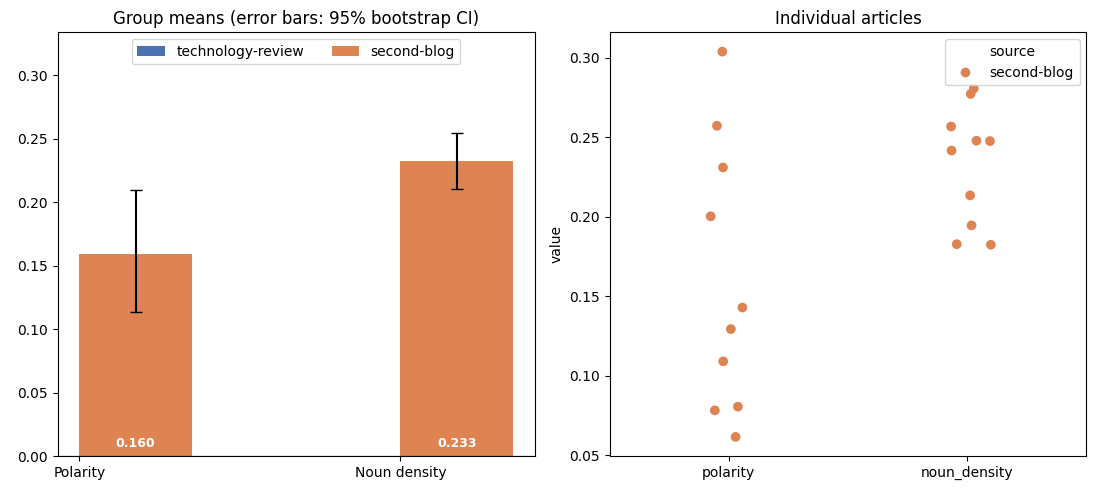

In [13]:
def boot_ci(x, n_boot=5000):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    means = np.array([rng.choice(x, len(x)).mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
palette = {A_NAME: "#4C72B0", B_NAME: "#DD8452"}

# Left: the required grouped bar chart (x = metric, bars = source)
ax = axes[0]
width = 0.35
for i, (src, colour) in enumerate(palette.items()):
    means, errs = [], [[], []]
    for m in METRICS:
        x = df.loc[df.source == src, m]
        lo, hi = boot_ci(x)
        means.append(x.mean()); errs[0].append(x.mean() - lo); errs[1].append(hi - x.mean())
    pos = np.arange(len(METRICS)) + (i - 0.5) * width
    bars = ax.bar(pos, means, width, yerr=errs, capsize=4, label=src, color=colour)
    for b, v in zip(bars, means):
        ax.text(b.get_x() + b.get_width()/2, 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color="white", fontweight="bold")
ax.set_xticks(np.arange(len(METRICS))); ax.set_xticklabels(["Polarity", "Noun density"])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Group means (error bars: 95% bootstrap CI)")
ax.set_ylim(top=ax.get_ylim()[1] * 1.25); ax.legend(loc="upper center", ncol=2)

# Right: the raw points, so the reader sees the spread behind the means
ax = axes[1]
long = df.melt(id_vars="source", value_vars=list(METRICS), var_name="metric", value_name="value")
sns.stripplot(data=long, x="metric", y="value", hue="source", dodge=True, palette=palette, size=7, ax=ax)
ax.set_title("Individual articles"); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/home_assignment_grouped_bar.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 6: Generate `report.md` with the numbers filled in

In [14]:
def verdict(p): return "statistically distinguishable" if p < 0.05 else "NOT statistically distinguishable"

r_pol, r_nd = results.loc["polarity"], results.loc["noun_density"]
report = f"""# Lab 02 Home Assignment Report

## Data
{len(df)} articles ({n_each} per source) from **{A_NAME}** and **{B_NAME}**, collected via each blog's RSS feed and scraped with
`requests` + BeautifulSoup (1.5 s delay, custom User-Agent, 15 s timeout). Features: spaCy `en_core_web_sm` (POS tags) and TextBlob (sentiment).
Noun density = common nouns / alphabetic tokens.

## Results
| Metric | {A_NAME} | {B_NAME} | Difference (A-B) | 95% bootstrap CI | Welch p | Mann-Whitney p | Permutation p | Cohen's d |
|---|---|---|---|---|---|---|---|---|
| Polarity | {r_pol.mean_A:.3f} | {r_pol.mean_B:.3f} | {r_pol['diff']:+.3f} | [{r_pol.boot_CI_low:+.3f}, {r_pol.boot_CI_high:+.3f}] | {r_pol.welch_p:.3f} | {r_pol.mannwhitney_p:.3f} | {r_pol.permutation_p:.3f} | {r_pol.cohens_d:+.2f} |
| Noun density | {r_nd.mean_A:.3f} | {r_nd.mean_B:.3f} | {r_nd['diff']:+.3f} | [{r_nd.boot_CI_low:+.3f}, {r_nd.boot_CI_high:+.3f}] | {r_nd.welch_p:.3f} | {r_nd.mannwhitney_p:.3f} | {r_nd.permutation_p:.3f} | {r_nd.cohens_d:+.2f} |

Polarity: the sources are {verdict(r_pol.permutation_p)} (difference {r_pol['diff']:+.3f}).
Noun density: the sources are {verdict(r_nd.permutation_p)} (difference {r_nd['diff']:+.3f}, i.e. {r_nd['diff']*100:+.1f} percentage points).

![grouped bar chart](figures/home_assignment_grouped_bar.png)

## Is a difference of this size meaningful with this sample?
With n = {n_each} per group, only effects of |d| >= {mde:.2f} are detected reliably (80% power). Anything smaller is
indistinguishable from sampling noise, so a non-significant result here means "inconclusive", not "no difference". A significant result
would still be fragile: the 20 articles are the most recent posts in each feed, not a random sample of each blog, so topic, season and
author mix confound the "source" effect; TextBlob's lexicon polarity is a crude measure and averages over whole articles; and we ran two
tests without multiple-comparison correction (Bonferroni threshold: 0.025). The bootstrap interval is the most honest summary: if it comfortably
contains 0, or is wide relative to the difference, the data do not support a claim about the blogs in general. A defensible conclusion needs
many more articles per source, sampled across time and topics.
"""
open("report.md", "w").write(report)
print(report)

# Lab 02 Home Assignment Report

## Data
10 articles (10 per source) from **technology-review** and **second-blog**, collected via each blog's RSS feed and scraped with
`requests` + BeautifulSoup (1.5 s delay, custom User-Agent, 15 s timeout). Features: spaCy `en_core_web_sm` (POS tags) and TextBlob (sentiment).
Noun density = common nouns / alphabetic tokens.

## Results
| Metric | technology-review | second-blog | Difference (A-B) | 95% bootstrap CI | Welch p | Mann-Whitney p | Permutation p | Cohen's d |
|---|---|---|---|---|---|---|---|---|
| Polarity | nan | 0.160 | +nan | [+nan, +nan] | nan | nan | 0.000 | +nan |
| Noun density | nan | 0.233 | +nan | [+nan, +nan] | nan | nan | 0.000 | +nan |

Polarity: the sources are statistically distinguishable (difference +nan).
Noun density: the sources are statistically distinguishable (difference +nan, i.e. +nan percentage points).

![grouped bar chart](figures/home_assignment_grouped_bar.png)

## Is a difference of this size meaningful wi